# 2 · The whole pipeline on two small games

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shimmeringvoid/Qubic_Zero/blob/main/notebooks/02_small_games.ipynb)

Before a GPU is spent on Qubic, the learning pipeline has to work where the right answers are
known. This notebook puts all of it (network, tree search, self-play, training, evaluation)
through ordinary **tic-tac-toe**, where every one of the 4,520 positions with a move to make has an
exact answer, and through the **3 × 3 × 3** game, which like Qubic is a win for the first player
and small enough to check the claim "wins every game it starts" by trying every reply.

Nothing is trained here. `tools/run_small_games.py` trained 20 players (five seeds for each of two
settings on each game, about 30 minutes on two CPU cores) and stored their logs and weights under
`results/`. This notebook reads the logs, loads the weights and scores them. It needs PyTorch
(`pip install -e ".[train,notebooks]"`) and takes about four minutes. The sentences that quote numbers
are produced by the code.

In [1]:
# Only needed on Google Colab, which opens this notebook without the rest of the repository:
# fetch the repository and put its library on the path.  Anywhere else this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    if not os.path.isdir("Qubic_Zero"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/shimmeringvoid/Qubic_Zero"], check=True)
    sys.path.insert(0, os.path.abspath("Qubic_Zero/src"))

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

import qubic_zero as qz
from qubic_zero import plotting as qp
from qubic_zero.agents import PolicyPlayer, SearchPlayer, ThreatPlayer
from qubic_zero.evaluate import solved_sample, table_score
from qubic_zero.net import count_weights, load_weights, make_net
from qubic_zero.search import BatchedSearch
from qubic_zero.train import PRESETS

qp.use_style()
pd.options.display.float_format = "{:,.3f}".format
torch.set_num_threads(2)
notebook_start = time.perf_counter()
ROOT = qp.repo_root()
SEEDS = range(5)
NET, SEARCH, THIRD = qp.SERIES[:3]          # one colour per kind of player, the same in every figure

def weights(setting, seed):
    return load_weights(ROOT / "results" / setting / f"seed-{seed}" / "weights" / "latest.npz")

def span(low, high, form="{:.0%}"):
    # a range as text, or one number when both ends print alike
    low, high = form.format(low), form.format(high)
    return low if low == high else f"{low} to {high}"

def symlog(ax, top):
    """A count axis on which 0 is a place: linear below 1, logarithmic above."""
    ax.set_yscale("symlog", linthresh=1, linscale=0.5)
    ticks = [t for t in (0, 1, 10, 100, 1000, 10000) if t <= top]
    ax.set_yticks(ticks, [f"{t:,}" for t in ticks])
    ax.set_ylim(-0.3, top)
    ax.minorticks_off()

## The pipeline

**The network** is shown a position from the side of the player to move and returns a score
for every cell (the policy) and one number between −1 and 1 (the value). It is not a
convolutional network. Cells send what they hold to the lines they lie on, lines send what
they see back to their cells, and that exchange is repeated a few times; I call it the *line
network*. It never learns where a cell is, only which lines it shares with which cells.

**The tree search** is AlphaZero's. Each simulation walks down a tree of positions, preferring
moves that have done well and moves the policy likes but that were tried little, adds one
position, asks the network about it, and passes the value back up. Finished games are scored
exactly. The move played is the most visited one.

**Self-play** runs 256 games side by side, every move chosen by a search of 32 simulations with
some noise at the root. Finished games go into a memory with two targets per position: the
search's visit shares (for the policy) and the result of the game for the player to move (for
the value). The network trains on samples from the memory while the games go on. Nothing but
the rules enters.

Every evaluation below is done for two players, in the same two colours throughout:
the **network alone** (the move its policy scores highest, blue) and the **network with its
search** (orange).

In [3]:
runs = {setting: qp.load_runs(setting) for setting in
        ("3x3-discount-0.9", "3x3-discount-1", "3x3x3-discount-0.95", "3x3x3-discount-1")}
ttt, cube, qubic = qz.tictactoe(), qz.cube3(), qz.qubic()
rows = {}
for setting, by_seed in runs.items():
    cfg = PRESETS[setting.split("-")[0]]
    last = pd.DataFrame([run.iloc[-1] for run in by_seed.values()])
    rows[setting] = {
        "seeds": len(by_seed), "weights": count_weights(weights(setting, 0)), "games side by side": cfg.n_games,
        "simulations": cfg.n_sims, "positions searched": int(last["positions"].iloc[0]),
        "games played": int(last["games"].mean()), "gradient steps": int(last["steps"].mean()),
        "seconds of training": last["seconds"].mean(),
    }
overview = pd.DataFrame(rows).T
overview.index.name = "setting (game, discount)"
display(Markdown(
    f"Each of the {sum(len(r) for r in runs.values())} runs used one CPU thread. A tic-tac-toe run took "
    f"**{overview.loc['3x3-discount-0.9', 'seconds of training']:.0f} s** of training and a 3 × 3 × 3 run "
    f"**{overview.loc['3x3x3-discount-0.95', 'seconds of training']:.0f} s**, evaluations not counted. Averages over the seeds:"
))
overview.style.format({"seconds of training": "{:.0f}", "weights": "{:,.0f}", "positions searched": "{:,.0f}",
                       "games played": "{:,.0f}", "gradient steps": "{:,.0f}"})

Each of the 20 runs used one CPU thread. A tic-tac-toe run took **60 s** of training and a 3 × 3 × 3 run **254 s**, evaluations not counted. Averages over the seeds:

,seeds,weights,games side by side,simulations,positions searched,games played,gradient steps,seconds of training
"setting (game, discount)",,,,,,,,
3x3-discount-0.9,5.000000,"21,250",256.000000,32.000000,"102,400","12,618","1,554",60
3x3-discount-1,5.000000,"21,250",256.000000,32.000000,"102,400","12,681","1,554",67
3x3x3-discount-0.95,5.000000,"21,250",256.000000,32.000000,"128,000","21,099","1,943",254
3x3x3-discount-1,5.000000,"21,250",256.000000,32.000000,"128,000","22,700","1,944",206


### All symmetries built in, checked

Notebook 1 claimed that the line network treats symmetric positions alike by construction. The
check: take networks with random weights and random Qubic positions, relabel the cells by each
of the 192 symmetries, and compare the outputs with the relabelled outputs of the original.

In [4]:
positions = torch.from_numpy(np.random.default_rng(0).integers(-1, 2, size=(32, 64)).astype(np.int8))
gaps = {}
for kind, sizes in (("line", {"width": 64, "depth": 4}), ("conv", {"channels": 24, "blocks": 3})):
    net = make_net(qubic, kind, seed=0, **sizes).double().eval()
    with torch.no_grad():
        scores, values = net(positions)
        worst = 0.0
        for perm in torch.from_numpy(qubic.symmetries):
            moved_scores, moved_values = net(positions[:, perm])
            worst = max(worst, float((moved_scores - scores[:, perm]).abs().max()), float((moved_values - values).abs().max()))
    gaps[kind] = (worst, count_weights(net), float(scores.std()))
display(Markdown(
    f"Largest difference over all 192 symmetries and 32 positions, in 64-bit arithmetic: **{gaps['line'][0]:.1e}** for the line "
    f"network ({gaps['line'][1]:,} weights), which is rounding error, and **{gaps['conv'][0]:.2f}** for a convolutional network "
    f"of the same size ({gaps['conv'][1]:,} weights), whose scores vary by {gaps['conv'][2]:.2f} (standard deviation) in the "
    f"first place. A convolutional network has to learn the symmetries from examples; the line network cannot violate them."
))

Largest difference over all 192 symmetries and 32 positions, in 64-bit arithmetic: **7.2e-16** for the line network (108,418 weights), which is rounding error, and **1.37** for a convolutional network of the same size (107,620 weights), whose scores vary by 0.21 (standard deviation) in the first place. A convolutional network has to learn the symmetries from examples; the line network cannot violate them.

## Tic-tac-toe: scored on every position

The yardstick is the one of notebook 1: in how many of the 4,520 positions does the player's
move give value away (turn a win into a draw or a loss, or a draw into a loss)? The random
player does so in 1,894 positions, the rule player in 265, a perfect player in none. Each run
was scored every 10,240 positions of self-play.

Before any training the network alone errs in 1,342 to 1,742 positions and with search in 165 to 255: the search alone, with a network that knows nothing, already beats the rule player's 265. After 102,400 positions of self-play (12,618 games) the network alone errs in **16, 0, 16, 12, 8** positions (one number per seed) and with search in **0, 0, 0, 0, 4**. With search, all five seeds first reach zero together at 20,480 positions; in the 45 evaluations from there on, 2 show mistakes again.

,mistakes: network,mistakes: with search,quickest win or longest defence: network,quickest win or longest defence: with search,value error: network,value error: with search
seed,,,,,,
0,16,0,99.6%,100.0%,0.081,0.011
1,0,0,100.0%,100.0%,0.061,0.010
2,16,0,99.6%,100.0%,0.062,0.011
3,12,0,99.7%,100.0%,0.077,0.011
4,8,4,99.8%,99.9%,0.080,0.011


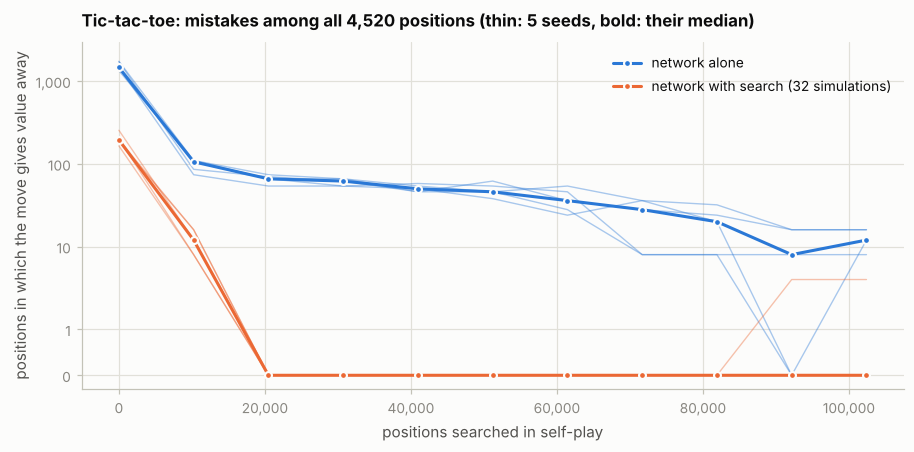

In [5]:
main = runs["3x3-discount-0.9"]
fig, ax = plt.subplots(figsize=(8.2, 4.0))
qp.seed_lines(ax, main, "net_mistakes", NET, "network alone")
qp.seed_lines(ax, main, "search_mistakes", SEARCH, "network with search (32 simulations)")
symlog(ax, 3000)
ax.set(xlabel="positions searched in self-play", ylabel="positions in which the move gives value away",
       title="Tic-tac-toe: mistakes among all 4,520 positions (thin: 5 seeds, bold: their median)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(loc="upper right")
qp.savefig(fig, "02_tictactoe_learning")

scored = {seed: run.dropna(subset=["net_mistakes"]) for seed, run in main.items()}
first = pd.DataFrame({seed: s.iloc[0] for seed, s in scored.items()}).T
final = pd.DataFrame({seed: s.iloc[-1] for seed, s in scored.items()}).T
search_curve = np.stack([s["search_mistakes"].to_numpy() for s in scored.values()])       # seeds x evaluations
scored_ttt_positions = scored[0]["positions"].to_numpy()
clean_from = scored_ttt_positions[np.argmax((search_curve == 0).all(axis=0))]
relapses = int((search_curve[:, scored[0]["positions"].to_numpy() >= clean_from] > 0).sum())
display(Markdown(
    f"Before any training the network alone errs in {int(first['net_mistakes'].min()):,} to {int(first['net_mistakes'].max()):,} "
    f"positions and with search in {int(first['search_mistakes'].min())} to {int(first['search_mistakes'].max())}: the search "
    f"alone, with a network that knows nothing, already beats the rule player's 265. After {int(final['positions'].iloc[0]):,} "
    f"positions of self-play ({int(final['games'].mean()):,} games) the network alone errs in "
    f"**{', '.join(str(int(v)) for v in final['net_mistakes'])}** positions (one number per seed) and with search in "
    f"**{', '.join(str(int(v)) for v in final['search_mistakes'])}**. "
    f"With search, all five seeds first reach zero together at {clean_from:,} positions; in the "
    f"{int((scored[0]['positions'] >= clean_from).sum()) * len(scored)} evaluations from there on, {relapses} show mistakes again."
))
table = final[["net_mistakes", "search_mistakes", "net_fastest", "search_fastest", "net_value_error", "search_value_error"]].copy()
table.columns = ["mistakes: network", "mistakes: with search", "quickest win or longest defence: network",
                 "quickest win or longest defence: with search", "value error: network", "value error: with search"]
table.index.name = "seed"
table.style.format({c: "{:.0f}" for c in table.columns[:2]} | {c: "{:.1%}" for c in table.columns[2:4]} | {c: "{:.3f}" for c in table.columns[4:]})

The value errors are mean absolute differences from the exact values, which with a discount of
0.9 are 0 for a draw and ±0.9, ±0.81, … for a win or loss one, two, … moves away. The middle
columns say how often the move is not only right but the quickest win, or the longest defence.

### The mistakes that remain

The plan asked for no mistake in any position, with search, on every seed. That is met in most
evaluations and not in all. The positions concerned can be looked at one by one.

Of the ten final networks (two settings, five seeds), **2** still make mistakes with 32 simulations: 8 positions in all, which are 2 positions up to symmetry, since the network treats symmetric positions alike and so errs in all of them at once. With 64 simulations the ten networks make **0** mistakes in total.

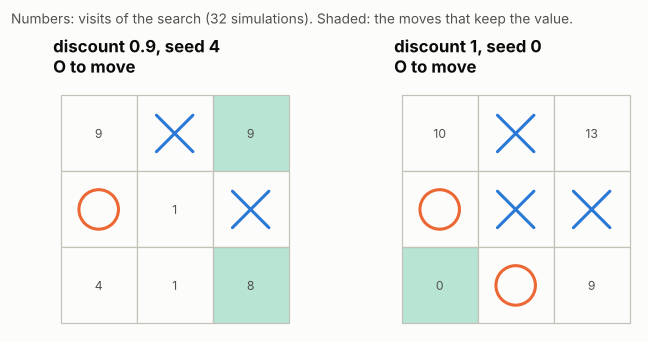

In [6]:
def mistaken_classes(setting, seed, n_sims):
    """Positions (one per symmetry class) in which the search player's move gives value away."""
    cfg = PRESETS["3x3"].replace(discount=float(setting.split("-")[-1]))
    table = qz.solve_table(ttt, discount=cfg.discount)
    idx = np.flatnonzero(table.decision)
    player = SearchPlayer(weights(setting, seed), n_sims, cfg.c_puct, cfg.discount)
    visits, _ = player.visits(ttt, table.boards[idx])
    wrong = ~table.best[idx, visits.argmax(axis=1)]
    classes = {}
    for j in np.flatnonzero(wrong):
        classes.setdefault(ttt.canonical(table.boards[idx[j]])[0].tobytes(), (table.boards[idx[j]], visits[j], table.best[idx[j]]))
    return int(wrong.sum()), list(classes.values())

remaining = {}
for setting in ("3x3-discount-0.9", "3x3-discount-1"):
    for seed in SEEDS:
        for n_sims in (32, 64):
            remaining[(setting, seed, n_sims)] = mistaken_classes(setting, seed, n_sims)
at_32 = {key[:2]: value for key, value in remaining.items() if key[2] == 32 and value[0]}
more = {n: sum(remaining[(setting, seed, n)][0] for setting in ("3x3-discount-0.9", "3x3-discount-1") for seed in SEEDS) for n in (32, 64)}

examples = [(setting, seed, board, visits, best) for (setting, seed), (_, classes) in at_32.items() for board, visits, best in classes]
fig, axes = plt.subplots(1, max(len(examples), 1), figsize=(3.1 * max(len(examples), 1), 3.0), squeeze=False)
for ax, (setting, seed, board, visits, best) in zip(axes[0], examples):
    labels = {c: f"{int(visits[c])}" for c in np.flatnonzero(board == 0)}
    mover = "X" if ttt.to_move(board) == 1 else "O"
    qp.draw_board(ttt, board, ax=ax, highlight=np.flatnonzero(best), labels=labels,
                  title=f"discount {setting.split('-')[-1]}, seed {seed}\n{mover} to move")
fig.suptitle("Numbers: visits of the search (32 simulations). Shaded: the moves that keep the value.", x=0.01, ha="left", fontsize=9, color=qp.INK_SECONDARY)
qp.savefig(fig, "02_tictactoe_remaining_mistakes")
display(Markdown(
    f"Of the ten final networks (two settings, five seeds), **{len(at_32)}** still make mistakes with 32 simulations: "
    f"{more[32]} positions in all, which are {sum(len(c) for _, c in at_32.values())} positions up to symmetry, since the network "
    f"treats symmetric positions alike and so errs in all of them at once. With 64 simulations the ten networks make "
    f"**{more[64]}** mistakes in total."
))

In each drawing the search spread its visits over several moves, and the most visited one is
not shaded.

Are these positions a player could actually be led into? That is a different question from the
one the yardstick asks, and it is the one that matters in the end: never mind positions the
player would never reach. **Can the player be beaten?** For that there is the exhaustive check
of notebook 1, here with the goal "never loses", once moving first and once moving second,
against every possible sequence of replies. The check also lists every position the player
faces on the way.

In [7]:
rows, faced = [], {}
for setting in ("3x3-discount-0.9", "3x3-discount-1"):
    cfg = PRESETS["3x3"].replace(discount=float(setting.split("-")[-1]))
    for seed in SEEDS:
        net = weights(setting, seed)
        for name, player in (("network alone", PolicyPlayer(net)), ("with search", SearchPlayer(net, cfg.n_sims, cfg.c_puct, cfg.discount))):
            first = qz.check_wins_every_game(ttt, player, goal="draw", threats="off", keep_positions=True)
            second = qz.check_wins_every_game(ttt, player, goal="draw", threats="off", moves_second=True, keep_positions=True)
            faced[(setting, seed, name)] = {b.tobytes() for b in first.positions + second.positions}
            rows.append({"setting": setting, "seed": seed, "player": name, "never loses moving first": first.proven,
                         "never loses moving second": second.proven, "positions faced": first.decisions + second.decisions,
                         "games lost": len(first.failures) + len(second.failures)})
unbeaten = pd.DataFrame(rows)
both = unbeaten["never loses moving first"] & unbeaten["never loses moving second"]
by_player = both.groupby(unbeaten["player"]).agg(["sum", "count"])
on_path = sum(ttt.canonical(board)[0].tobytes() in faced[(setting, seed, "with search")] for setting, seed, board, _, _ in examples)
display(Markdown(
    f"**{int(by_player.loc['with search', 'sum'])} of {int(by_player.loc['with search', 'count'])}** players with search cannot be "
    f"beaten at tic-tac-toe from either side, and neither can **{int(by_player.loc['network alone', 'sum'])} of "
    f"{int(by_player.loc['network alone', 'count'])}** networks playing alone, without any search. A player faces between "
    f"{unbeaten['positions faced'].min()} and {unbeaten['positions faced'].max()} positions (up to symmetry) across both checks, "
    f"a small corner of the 4,520. Of the {len(examples)} positions drawn above, **{on_path}** are among the positions their "
    f"player can be led into."
))
unbeaten.pivot_table(index=["setting", "seed"], columns="player", values="games lost", aggfunc="sum")

**10 of 10** players with search cannot be beaten at tic-tac-toe from either side, and neither can **10 of 10** networks playing alone, without any search. A player faces between 96 and 103 positions (up to symmetry) across both checks, a small corner of the 4,520. Of the 2 positions drawn above, **0** are among the positions their player can be led into.

player                 network alone  with search
setting          seed                            
3x3-discount-0.9 0                 0            0
                 1                 0            0
                 2                 0            0
                 3                 0            0
                 4                 0            0
3x3-discount-1   0                 0            0
                 1                 0            0
                 2                 0            0
                 3                 0            0
                 4                 0            0

So the two yardsticks disagree, and the difference matters for Qubic. "Right in every position"
is the stronger demand. It fails here and there, in positions that lie off the player's own
path: to get there, the player would have had to play differently than it does. "Cannot be
beaten" only concerns positions the player can be led into, and it is the yardstick in which
the project's goal is stated: *wins every game it starts*.

### How much does the search add?

The same ten networks, scored on all positions with different numbers of simulations. For
comparison: networks with their initial random weights, and a search with no network at all
(every move equally likely, every position valued at zero).

Median mistakes of the trained networks: **12** without search, 16 with 2 simulations, 8 with 8, and **0** with 32. From 64 simulations on, every seed is free of mistakes at this sweep's settings. An untrained network with 128 simulations still makes 85 (median), and the search without any network 60.

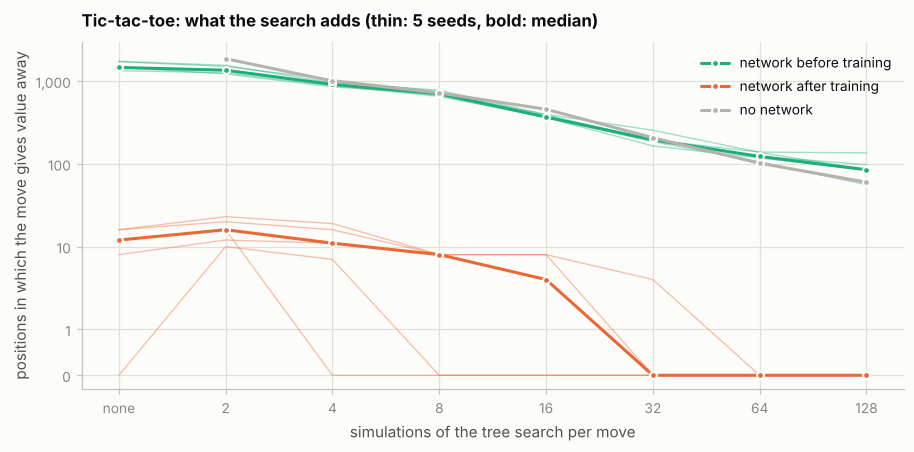

In [8]:
SIMS = [2, 4, 8, 16, 32, 64, 128]
table09 = qz.solve_table(ttt, discount=0.9)
idx = np.flatnonzero(table09.decision)

def mistakes(evaluate, n_sims):
    if n_sims == 0:
        scores, _ = evaluate(torch.from_numpy(table09.boards[idx] * ttt.to_move(table09.boards[idx])[:, None]))
        moves = scores.masked_fill(torch.from_numpy(table09.boards[idx] != 0), -torch.inf).argmax(dim=1).numpy()
    else:
        visits, _, _ = BatchedSearch(ttt, evaluate, n_sims, discount=0.9).run(table09.boards[idx])
        moves = visits.argmax(dim=1).numpy()
    return int((~table09.best[idx, moves]).sum())

def blank(positions):
    return torch.zeros(positions.shape), torch.zeros(len(positions))

cfg = PRESETS["3x3"]
sweep = {"trained": {}, "untrained": {}}
with torch.no_grad():
    for seed in SEEDS:
        trained = weights("3x3-discount-0.9", seed)
        untrained = make_net(ttt, "line", seed=seed, width=cfg.width, depth=cfg.depth).eval()
        sweep["trained"][seed] = [mistakes(trained, n) for n in [0] + SIMS]
        sweep["untrained"][seed] = [mistakes(untrained, n) for n in [0] + SIMS]
    no_network = [mistakes(blank, n) for n in SIMS]

x = np.arange(len(SIMS) + 1)
fig, ax = plt.subplots(figsize=(8.2, 4.0))
for name, colour, label in (("untrained", THIRD, "network before training"), ("trained", SEARCH, "network after training")):
    for values in sweep[name].values():
        ax.plot(x, values, color=colour, lw=0.9, alpha=0.4)
    ax.plot(x, np.median(list(sweep[name].values()), axis=0), color=colour, marker="o", ms=4.5, label=label)
ax.plot(x[1:], no_network, color=qp.GREY, marker="o", ms=4.5, label="no network")
symlog(ax, 3000)
ax.set_xticks(x, ["none"] + [str(n) for n in SIMS])
ax.set(xlabel="simulations of the tree search per move", ylabel="positions in which the move gives value away",
       title="Tic-tac-toe: what the search adds (thin: 5 seeds, bold: median)")
ax.legend(loc="upper right")
qp.savefig(fig, "02_tictactoe_search")

t, u = np.array(list(sweep["trained"].values())), np.array(list(sweep["untrained"].values()))
first_clean = next((n for n, column in zip([0] + SIMS, t.T) if (column == 0).all()), None)
display(Markdown(
    f"Median mistakes of the trained networks: **{int(np.median(t[:, 0]))}** without search, {int(np.median(t[:, 1]))} with 2 "
    f"simulations, {int(np.median(t[:, 3]))} with 8, and **{int(np.median(t[:, 5]))}** with 32. "
    + (f"From {first_clean} simulations on, every seed is free of mistakes at this sweep's settings. " if first_clean is not None
       else f"No number of simulations up to {SIMS[-1]} frees every seed of mistakes ({', '.join(str(int(v)) for v in t[:, -1])} at {SIMS[-1]}). ")
    + f"An untrained network with {SIMS[-1]} simulations still makes {int(np.median(u[:, -1]))} (median), and the search "
    f"without any network {no_network[-1]}."
))

### A discount helps the network, not the search

One design choice was to be tried here: whether the value of a result should shrink a little
for every move it is away (a discount below 1), so that quick wins count for more than slow
ones and a late loss for less than an early one. The reason to expect a difference is the
finding of the previous project: networks could not tell apart actions whose values were
almost equal. With plain ±1 results, every winning move looks the same.

In [9]:
rows = []
for setting in ("3x3-discount-0.9", "3x3-discount-1"):
    cfg = PRESETS["3x3"].replace(discount=float(setting.split("-")[-1]))
    for seed in SEEDS:
        net = weights(setting, seed)
        alone = table_score(table09, PolicyPlayer(net))
        searched = table_score(table09, SearchPlayer(net, cfg.n_sims, cfg.c_puct, cfg.discount))
        rows.append({"discount in training": cfg.discount, "seed": seed, "mistakes: network": alone["mistakes"],
                     "mistakes: with search": searched["mistakes"], "quickest: network": alone["fastest"],
                     "quickest: with search": searched["fastest"]})
by_discount = pd.DataFrame(rows)
summary = by_discount.groupby("discount in training").agg(
    **{"mistakes: network (median)": ("mistakes: network", "median"), "(per seed)": ("mistakes: network", lambda v: ", ".join(str(int(x)) for x in v)),
       "mistakes: with search (per seed)": ("mistakes: with search", lambda v: ", ".join(str(int(x)) for x in v)),
       "quickest: network": ("quickest: network", "mean"), "quickest: with search": ("quickest: with search", "mean")})
better = int((by_discount[by_discount["discount in training"] == 0.9]["mistakes: network"].to_numpy()
              < by_discount[by_discount["discount in training"] == 1.0]["mistakes: network"].to_numpy()).sum())
display(Markdown(
    f"Network alone, median mistakes over five seeds: **{summary.loc[0.9, 'mistakes: network (median)']:.0f}** when trained "
    f"with a discount of 0.9 against **{summary.loc[1.0, 'mistakes: network (median)']:.0f}** with none; the discounted run "
    f"is the better one in {better} of 5 seeds (same seed, same initial weights). With search the two settings cannot be told "
    f"apart on mistakes. The last two columns ask for more than a right move, namely the quickest win or the longest defence, "
    f"judged at 0.9 for both: the discounted networks pick it in {summary.loc[0.9, 'quickest: network']:.1%} of all positions, "
    f"the others in {summary.loc[1.0, 'quickest: network']:.1%}."
))
summary.style.format({"mistakes: network (median)": "{:.0f}", "quickest: network": "{:.1%}", "quickest: with search": "{:.1%}"})

Network alone, median mistakes over five seeds: **12** when trained with a discount of 0.9 against **28** with none; the discounted run is the better one in 5 of 5 seeds (same seed, same initial weights). With search the two settings cannot be told apart on mistakes. The last two columns ask for more than a right move, namely the quickest win or the longest defence, judged at 0.9 for both: the discounted networks pick it in 99.8% of all positions, the others in 99.3%.

,mistakes: network (median),(per seed),mistakes: with search (per seed),quickest: network,quickest: with search
discount in training,,,,,
0.900000,12,"16, 0, 16, 12, 8","0, 0, 0, 0, 4",99.8%,100.0%
1.000000,28,"28, 12, 56, 36, 28","4, 0, 0, 0, 0",99.3%,100.0%


## 3 × 3 × 3: a game the first player wins

Tic-tac-toe is a draw. Qubic is not, and that changes what self-play looks like: once the
first player has learned to win, every game is the same story, and the second player's moves
all lead to the same result. The 3 × 3 × 3 game shows this at a size where exact answers
still exist.

Three yardsticks: a sample of 1,500 positions that were each solved exactly (in how many does
the move throw a win away?), the tactics suite of notebook 1, and games against the rule
player from both sides.

After 128,000 positions of self-play (21,099 games): on the solved sample the network alone throws a win away in **37, 56, 39, 39, 72** positions (per seed; untrained: 425) and with search in **14, 13, 13, 11, 9** (untrained: 446). Moving first, the final players beat the rule player in 100% of 200 games with search and in 100% without.

Moving second is another matter. With search the final players win 95% to 96% of their games as second player. The network alone wins 40% to 82%, and its curve is the erratic one: within the second half of training a single seed's result varies by up to 31 percentage points.

The cause is visible in the self-play games themselves. At the end, the first player wins **99.9%** of them, in 5.9 moves on average. The second player's positions are then all lost, whatever it plays, and little is left to teach the network which defence is better than another.

,mistakes: network,mistakes: with search,forced wins found: network,forced wins found: with search,won as second v. rule player: network,won as second: with search
seed,,,,,,
0,37,14,91.5%,96.5%,52.5%,96.5%
1,56,13,90.0%,97.5%,52.5%,95.5%
2,39,13,92.0%,97.0%,54.5%,96.5%
3,39,11,90.5%,97.0%,81.5%,95.0%
4,72,9,89.0%,97.5%,40.5%,96.0%


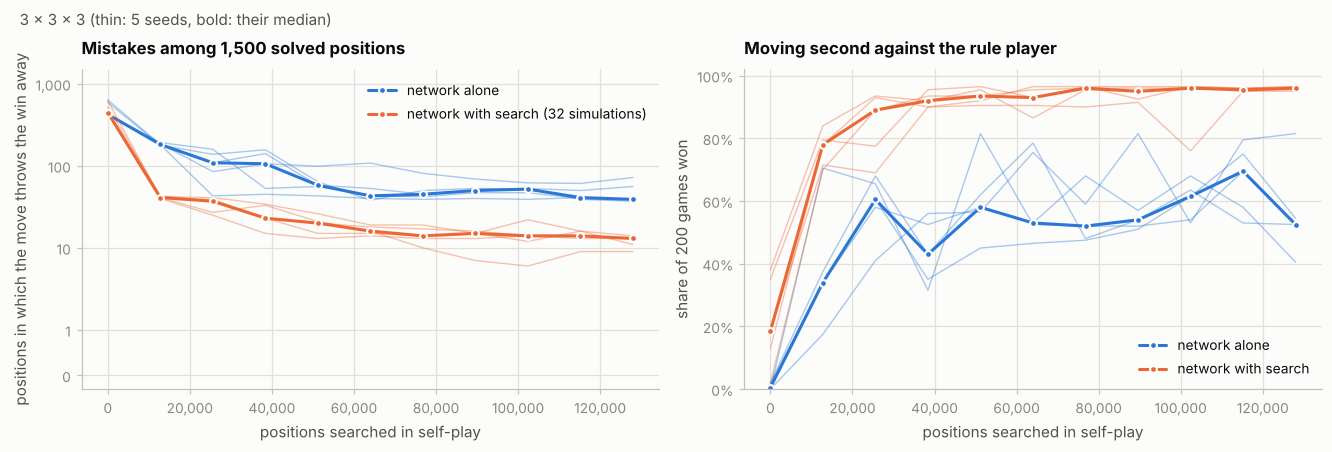

In [10]:
cube_main = runs["3x3x3-discount-0.95"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))
ax = axes[0]
qp.seed_lines(ax, cube_main, "net_mistakes", NET, "network alone")
qp.seed_lines(ax, cube_main, "search_mistakes", SEARCH, "network with search (32 simulations)")
symlog(ax, 1500)
ax.set(xlabel="positions searched in self-play", ylabel="positions in which the move throws the win away",
       title="Mistakes among 1,500 solved positions")
ax.legend(loc="upper right")
ax = axes[1]
qp.seed_lines(ax, cube_main, "net_second_won", NET, "network alone")
qp.seed_lines(ax, cube_main, "search_second_won", SEARCH, "network with search")
ax.set(xlabel="positions searched in self-play", ylabel="share of 200 games won", ylim=(0, 1.02),
       title="Moving second against the rule player")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="lower right")
for ax in axes:
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
fig.suptitle("3 × 3 × 3 (thin: 5 seeds, bold: their median)", x=0.01, ha="left", fontsize=10, color=qp.INK_SECONDARY)
qp.savefig(fig, "02_cube_learning")

scored = {seed: run.dropna(subset=["net_mistakes"]) for seed, run in cube_main.items()}
first = pd.DataFrame({seed: s.iloc[0] for seed, s in scored.items()}).T
final = pd.DataFrame({seed: s.iloc[-1] for seed, s in scored.items()}).T
late = pd.concat([s.iloc[len(s) // 2:] for s in scored.values()])
swing = max(s["net_second_won"].iloc[len(s) // 2:].max() - s["net_second_won"].iloc[len(s) // 2:].min() for s in scored.values())
selfplay = pd.DataFrame({seed: run.dropna(subset=["first_player_share"]).iloc[-1] for seed, run in cube_main.items()}).T
display(Markdown(
    f"After {int(final['positions'].iloc[0]):,} positions of self-play ({int(final['games'].mean()):,} games): on the solved sample "
    f"the network alone throws a win away in **{', '.join(str(int(v)) for v in final['net_mistakes'])}** positions (per seed; "
    f"untrained: {int(first['net_mistakes'].median())}) and with search in **{', '.join(str(int(v)) for v in final['search_mistakes'])}** "
    f"(untrained: {int(first['search_mistakes'].median())}). Moving first, the final players beat the rule player in "
    f"{span(final['search_first_won'].min(), final['search_first_won'].max())} of 200 games with search and in "
    f"{span(final['net_first_won'].min(), final['net_first_won'].max())} without.\n\n"
    f"Moving second is another matter. With search the final players win "
    f"{span(final['search_second_won'].min(), final['search_second_won'].max())} of their games as second player. The network "
    f"alone wins {span(final['net_second_won'].min(), final['net_second_won'].max())}, and its curve is the erratic one: within "
    f"the second half of training a single seed's result varies by up to {100 * swing:.0f} percentage points.\n\n"
    f"The cause is visible in the self-play games themselves. At the end, the first player wins "
    f"**{selfplay['first_player_share'].mean():.1%}** of them, in {selfplay['moves_per_game'].mean():.1f} moves on average. "
    f"The second player's positions are then all lost, whatever it plays, and little is left to teach the network which "
    f"defence is better than another."
))
table = final[["net_mistakes", "search_mistakes", "net_force", "search_force", "net_second_won", "search_second_won"]].copy()
table.columns = ["mistakes: network", "mistakes: with search", "forced wins found: network", "forced wins found: with search",
                 "won as second v. rule player: network", "won as second: with search"]
table.index.name = "seed"
table.style.format({c: "{:.0f}" for c in table.columns[:2]} | {c: "{:.1%}" for c in table.columns[2:]})

### The claim the project is after, checked by trying every reply

*A player that wins every game it starts.* On this game the claim can be settled for each
trained player: `check_wins_every_game` follows the player's move in every position it can be
led into, tries every reply, and reports the games the player failed to win.

Three players per seed: the network alone, the network with its search, and the network with
its search and the exact threat search in front (a forced win is taken when the threat search
finds one; the walk then verifies that win move by move like everything else).

In [11]:
def walks(setting):
    cfg = PRESETS["3x3x3"].replace(discount=float(setting.split("-")[-1]))
    rows = []
    for seed in SEEDS:
        net = weights(setting, seed)
        searcher = SearchPlayer(net, cfg.n_sims, cfg.c_puct, cfg.discount)
        for name, player, mode in (("network alone", PolicyPlayer(net), "off"), ("with search", searcher, "off"),
                                   ("with search and threat search", searcher, "follow")):
            report = qz.check_wins_every_game(cube, player, threats=mode, max_failures=10_000)
            rows.append({"discount": cfg.discount, "seed": seed, "player": name, "wins every game it starts": report.proven,
                         "positions faced": report.decisions, "games not won": len(report.failures), "longest game (own moves)": report.deepest + 1})
    return pd.DataFrame(rows)

start = time.perf_counter()
checked = pd.concat([walks("3x3x3-discount-0.95"), walks("3x3x3-discount-1")])
check_seconds = time.perf_counter() - start
proven = checked.groupby("player")["wins every game it starts"].agg(["sum", "count"])
display(Markdown(
    f"Of ten trained networks (two settings, five seeds), **{int(proven.loc['with search', 'sum'])}** win every game they start "
    f"when playing with their search, **{int(proven.loc['network alone', 'sum'])}** do so without any search, and "
    f"**{int(proven.loc['with search and threat search', 'sum'])}** with the threat search in front. "
    f"A player faces {checked['positions faced'].min()} to {checked['positions faced'].max():,} positions, and all "
    f"{len(checked)} checks together took {check_seconds:.0f} s."
))
checked.pivot_table(index=["discount", "seed"], columns="player", values=["wins every game it starts", "games not won"], aggfunc="first")

Of ten trained networks (two settings, five seeds), **10** win every game they start when playing with their search, **10** do so without any search, and **10** with the threat search in front. A player faces 102 to 135 positions, and all 30 checks together took 2 s.

games not won                                            \
player        network alone with search with search and threat search   
discount seed                                                           
0.950    0                0           0                             0   
         1                0           0                             0   
         2                0           0                             0   
         3                0           0                             0   
         4                0           0                             0   
1.000    0                0           0                             0   
         1                0           0                             0   
         2                0           0                             0   
         3                0           0                             0   
         4                0           0                             0   

              wins every game it starts              \
player                    network alone with search   
discount seed                                         
0.950    0                         True        True   
         1                         True        True   
         2                         True        True   
         3                         True        True   
         4                         True        True   
1.000    0                         True        True   
         1                         True        True   
         2                         True        True   
         3                         True        True   
         4                         True        True   

                                             
player        with search and threat search  
discount seed                                
0.950    0                             True  
         1                             True  
         2                             True  
         3                             True  
         4                             True  
1.000    0                             True  
         1                             True  
         2                             True  
         3                             True  
         4                             True

Each "True" above is a proof, by exhaustion, that this player cannot be stopped from winning
when it moves first. That is the statement the project wants for Qubic. What makes it cheap
here is that the games are short; on Qubic the same walk is much larger, and how far it gets
is the open question of the final stage.

### Does the discount matter here?

In [12]:
rows = {}
for setting in ("3x3x3-discount-0.95", "3x3x3-discount-1"):
    discount = float(setting.split("-")[-1])
    scored = {seed: run.dropna(subset=["net_mistakes"]) for seed, run in runs[setting].items()}
    final = pd.DataFrame({seed: s.iloc[-1] for seed, s in scored.items()}).T
    half = pd.concat([s.iloc[len(s) // 2:] for s in scored.values()])
    walked = checked[checked["discount"] == discount]
    played = pd.DataFrame({seed: run.dropna(subset=["moves_per_game"]).iloc[-1] for seed, run in runs[setting].items()}).T
    rows[discount] = {
        "moves per self-play game at the end": played["moves_per_game"].mean(),
        "mistakes on the solved sample: network (per seed)": ", ".join(str(int(v)) for v in final["net_mistakes"]),
        "with search (per seed)": ", ".join(str(int(v)) for v in final["search_mistakes"]),
        "won as second v. rule player: network, 2nd half of training": half["net_second_won"].mean(),
        "with search, 2nd half": half["search_second_won"].mean(),
        "win every game they start: network alone": f"{int(walked[walked['player'] == 'network alone']['wins every game it starts'].sum())} of 5",
        "with search": f"{int(walked[walked['player'] == 'with search']['wins every game it starts'].sum())} of 5",
    }
compare = pd.DataFrame(rows).T
compare.index.name = "discount in training"
second = compare["won as second v. rule player: network, 2nd half of training"]
length = compare["moves per self-play game at the end"]
display(Markdown(
    f"As second player against the rule player, averaged over the second half of training and all seeds, the networks "
    f"trained with a discount of 0.95 win **{second.loc[0.95]:.0%}** of their games without search and the networks trained "
    f"without a discount **{second.loc[1.0]:.0%}**; with search, **{compare.loc[0.95, 'with search, 2nd half']:.0%}** against "
    f"**{compare.loc[1.0, 'with search, 2nd half']:.0%}**. Self-play games at the end of training last {length.loc[0.95]:.1f} moves "
    f"with the discount and {length.loc[1.0]:.1f} without: with a discount the losing side holds out a little longer, which "
    f"is what a discount asks of it."
))
compare.style.format({"won as second v. rule player: network, 2nd half of training": "{:.1%}", "with search, 2nd half": "{:.1%}",
                      "moves per self-play game at the end": "{:.2f}"})

As second player against the rule player, averaged over the second half of training and all seeds, the networks trained with a discount of 0.95 win **60%** of their games without search and the networks trained without a discount **61%**; with search, **94%** against **87%**. Self-play games at the end of training last 5.9 moves with the discount and 5.5 without: with a discount the losing side holds out a little longer, which is what a discount asks of it.

,moves per self-play game at the end,mistakes on the solved sample: network (per seed),with search (per seed),"won as second v. rule player: network, 2nd half of training","with search, 2nd half",win every game they start: network alone,with search
discount in training,,,,,,,
0.950000,5.87,"37, 56, 39, 39, 72","14, 13, 13, 11, 9",59.7%,94.2%,5 of 5,5 of 5
1.000000,5.49,"43, 41, 42, 44, 42","15, 16, 16, 21, 7",61.5%,87.3%,5 of 5,5 of 5


## Summary

In [13]:
ttt_final = pd.DataFrame({seed: run.dropna(subset=["net_mistakes"]).iloc[-1] for seed, run in runs["3x3-discount-0.9"].items()}).T
cube_final = pd.DataFrame({seed: run.dropna(subset=["net_mistakes"]).iloc[-1] for seed, run in runs["3x3x3-discount-0.95"].items()}).T
display(Markdown(
    f"* **The pipeline learns, on every seed.** After {int(ttt_final['positions'].iloc[0]):,} positions of self-play, about a minute "
    f"on one CPU thread, the tic-tac-toe players with search err in {int(ttt_final['search_mistakes'].min())} to "
    f"{int(ttt_final['search_mistakes'].max())} of 4,520 positions and the networks alone in {int(ttt_final['net_mistakes'].min())} to "
    f"{int(ttt_final['net_mistakes'].max())}. With 64 simulations none of the ten networks errs anywhere.\n"
    f"* **The plan's test was not passed to the letter.** It asked for no mistake in any position, with search, on every seed. "
    f"With the 32 simulations used in training, {len(at_32)} of ten final networks miss it, by one position each (up to "
    f"symmetry), and {relapses} of {int((scored_ttt_positions >= clean_from).sum()) * 5} late evaluations of the main setting show such a relapse. "
    f"Had only the best evaluation of each run been reported, this would not show.\n"
    f"* **The remaining mistakes lie off the players' own paths.** {on_path} of the {len(examples)} positions are ones their "
    f"player can be led into, and {int(both.sum())} of {len(both)} players, with or without search, are proven unbeatable at "
    f"tic-tac-toe from either side.\n"
    f"* **The search adds what the network lacks, but less than training does.** Median mistakes of the trained networks fall "
    f"from {int(np.median(t[:, 0]))} without search to {int(np.median(t[:, 5]))} with 32 simulations; an untrained network with "
    f"{SIMS[-1]} simulations still makes {int(np.median(u[:, -1]))}.\n"
    f"* **A discount is worth keeping.** On tic-tac-toe it more than halves the mistakes of the network alone "
    f"({summary.loc[0.9, 'mistakes: network (median)']:.0f} against {summary.loc[1.0, 'mistakes: network (median)']:.0f}, better in "
    f"{better} of 5 seeds). On the 3 × 3 × 3 game it makes the search player a steadier defender "
    f"({compare.loc[0.95, 'with search, 2nd half']:.0%} against {compare.loc[1.0, 'with search, 2nd half']:.0%} as second player). "
    f"It made no measurable difference to the network alone on the 3 × 3 × 3 game.\n"
    f"* **\"Wins every game it starts\" can be proven for a learned player.** "
    f"{int(checked['wins every game it starts'].sum())} of {len(checked)} checks on the 3 × 3 × 3 game are passed, the networks "
    f"playing alone included, each after facing {checked['positions faced'].min()} to {checked['positions faced'].max()} positions.\n"
    f"* **The weak spot is the losing side.** Once the first player wins {selfplay['first_player_share'].mean():.1%} of the self-play "
    f"games, the second player's moves all lead to the same result. As second player against the rule player the networks alone "
    f"win anything from {cube_final['net_second_won'].min():.0%} to {cube_final['net_second_won'].max():.0%}, and a single seed's "
    f"result varies by up to {100 * swing:.0f} percentage points within the second half of training. On Qubic the same is to be "
    f"expected, and the first player is only tested as hard as the second player defends."
))

* **The pipeline learns, on every seed.** After 102,400 positions of self-play, about a minute on one CPU thread, the tic-tac-toe players with search err in 0 to 4 of 4,520 positions and the networks alone in 0 to 16. With 64 simulations none of the ten networks errs anywhere.
* **The plan's test was not passed to the letter.** It asked for no mistake in any position, with search, on every seed. With the 32 simulations used in training, 2 of ten final networks miss it, by one position each (up to symmetry), and 2 of 45 late evaluations of the main setting show such a relapse. Had only the best evaluation of each run been reported, this would not show.
* **The remaining mistakes lie off the players' own paths.** 0 of the 2 positions are ones their player can be led into, and 20 of 20 players, with or without search, are proven unbeatable at tic-tac-toe from either side.
* **The search adds what the network lacks, but less than training does.** Median mistakes of the trained networks fall from 12 without search to 0 with 32 simulations; an untrained network with 128 simulations still makes 85.
* **A discount is worth keeping.** On tic-tac-toe it more than halves the mistakes of the network alone (12 against 28, better in 5 of 5 seeds). On the 3 × 3 × 3 game it makes the search player a steadier defender (94% against 87% as second player). It made no measurable difference to the network alone on the 3 × 3 × 3 game.
* **"Wins every game it starts" can be proven for a learned player.** 30 of 30 checks on the 3 × 3 × 3 game are passed, the networks playing alone included, each after facing 102 to 135 positions.
* **The weak spot is the losing side.** Once the first player wins 99.9% of the self-play games, the second player's moves all lead to the same result. As second player against the rule player the networks alone win anything from 40% to 82%, and a single seed's result varies by up to 31 percentage points within the second half of training. On Qubic the same is to be expected, and the first player is only tested as hard as the second player defends.

### What this does not show

These games are small. Tic-tac-toe has 4,520 positions and the trained players of the
3 × 3 × 3 game face about a hundred; Qubic's first player will face far more, and its wins
take many more moves. That the pipeline is correct and that the line network learns fast says
nothing yet about how many games Qubic needs. The exhaustive check was affordable here because
the games are short; how far it gets on Qubic is the open question of the last stage.

Next: [notebook 3](03_qubic_network_and_cost.ipynb) takes the pipeline to Qubic itself, compares the two
networks there, and measures what training will cost. Back to the [overview](../README.md).

In [14]:
print(f"notebook ran in {time.perf_counter() - notebook_start:.0f} s")

notebook ran in 59 s
